In [25]:
import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt

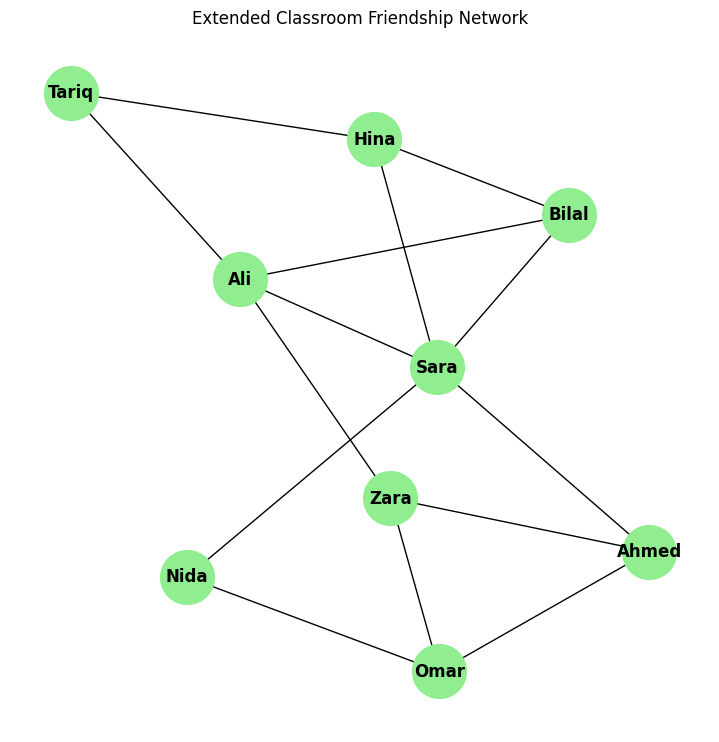

In [26]:
#Task 1
G = nx.Graph()
G.add_edges_from([
    ("Ali", "Sara"), ("Sara", "Ahmed"),
    ("Ahmed", "Zara"), ("Zara", "Ali"),
    ("Ali", "Bilal"), ("Bilal", "Sara"),
    ("Hina", "Sara"), ("Hina", "Bilal"),
    ("Omar", "Ahmed"), ("Omar", "Zara"),
    ("Tariq", "Ali"), ("Tariq", "Hina"),
    ("Nida", "Sara"), ("Nida", "Omar")
])

# Draw network
plt.figure(figsize=(7,7))
pos = nx.spring_layout(G, seed=7)
nx.draw(
    G, pos, with_labels=True,
    node_size=1500, node_color="lightgreen",
    font_size=12, font_weight="bold"
)
plt.title("Extended Classroom Friendship Network")
plt.show()

In [27]:
# Degrees
degrees = dict(G.degree())
print("Degrees:", degrees)

# Most social students
max_degree = max(degrees.values())
most_social = [student for student, deg in degrees.items() if deg == max_degree]
print("Most social student(s):", most_social)

Degrees: {'Ali': 4, 'Sara': 5, 'Ahmed': 3, 'Zara': 3, 'Bilal': 3, 'Hina': 3, 'Omar': 3, 'Tariq': 2, 'Nida': 2}
Most social student(s): ['Sara']


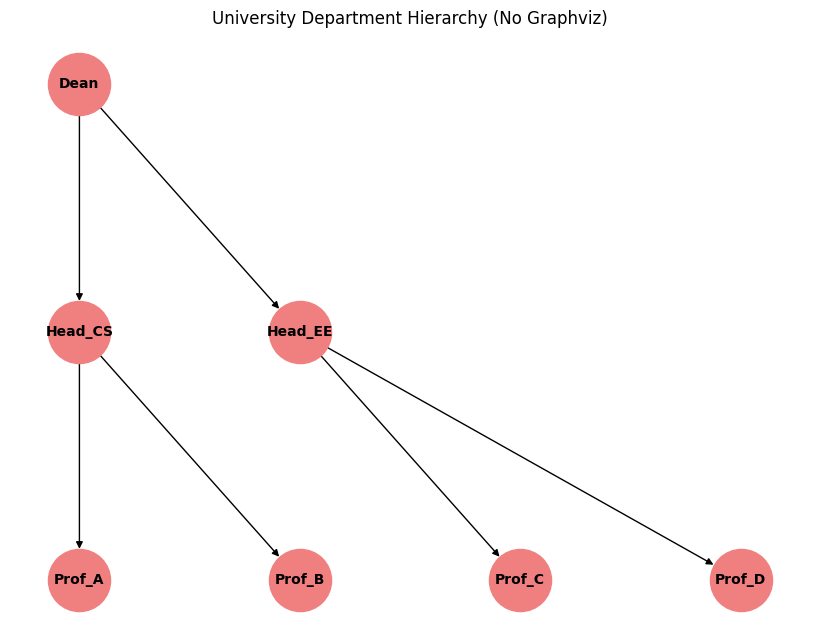

In [28]:
#Task 2

H = nx.DiGraph()
H.add_edges_from([
    ("Dean", "Head_CS"), ("Dean", "Head_EE"),
    ("Head_CS", "Prof_A"), ("Head_CS", "Prof_B"),
    ("Head_EE", "Prof_C"), ("Head_EE", "Prof_D")
])

levels = {
    "Dean": 0,
    "Head_CS": 1, "Head_EE": 1,
    "Prof_A": 2, "Prof_B": 2, "Prof_C": 2, "Prof_D": 2
}

# Position nodes by (level, index)
pos = {}
for level in set(levels.values()):
    nodes_at_level = [n for n, lvl in levels.items() if lvl == level]
    for i, node in enumerate(nodes_at_level):
        pos[node] = (i, -level)

plt.figure(figsize=(8,6))
nx.draw(
    H, pos, with_labels=True, arrows=True,
    node_size=2000, node_color="lightcoral",
    font_size=10, font_weight="bold"
)
plt.title("University Department Hierarchy (No Graphviz)")
plt.show()


In [29]:
# Analysis
in_degrees = dict(H.in_degree())
out_degrees = dict(H.out_degree())
print("In-degrees:", in_degrees)
print("Out-degrees:", out_degrees)

# Depth (longest path length)
all_paths = []
for target in H.nodes():
    if nx.has_path(H, "Dean", target):
        for path in nx.all_simple_paths(H, source="Dean", target=target):
            all_paths.append(path)

longest_path = max(all_paths, key=len)
depth = len(longest_path) - 1
print("Longest path (hierarchy chain):", longest_path)
print("Depth of hierarchy:", depth)


In-degrees: {'Dean': 0, 'Head_CS': 1, 'Head_EE': 1, 'Prof_A': 1, 'Prof_B': 1, 'Prof_C': 1, 'Prof_D': 1}
Out-degrees: {'Dean': 2, 'Head_CS': 2, 'Head_EE': 2, 'Prof_A': 0, 'Prof_B': 0, 'Prof_C': 0, 'Prof_D': 0}
Longest path (hierarchy chain): ['Dean', 'Head_CS', 'Prof_A']
Depth of hierarchy: 2


In [30]:
#Task 3

G = nx.Graph()
G.add_edges_from([
    ("Ali", "Sara"), ("Ali", "Bilal"),
    ("Sara", "Ahmed"), ("Sara", "Zara"),
    ("Ahmed", "Zara"), ("Bilal", "Hina"),
    ("Hina", "Usman"), ("Usman", "Zara"),
    ("Ahmed", "Omar"), ("Omar", "Hina")
])

target = "Ali"

friends = set(G.neighbors(target))
all_users = set(G.nodes())
non_friends = all_users - friends - {target}


mutual_counts = {}
for user in non_friends:
    mutual = friends & set(G.neighbors(user))
    mutual_counts[user] = len(mutual)

recommended = sorted(mutual_counts.items(), key=lambda x: -x[1])[:2]
print("Top 2 recommendations for", target, ":", recommended)


Top 2 recommendations for Ali : [('Ahmed', 1), ('Hina', 1)]


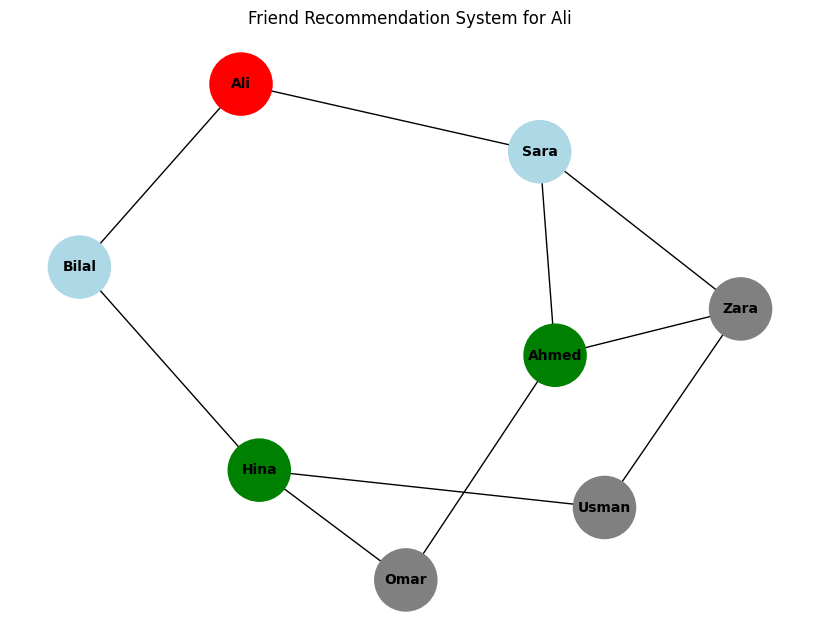

In [31]:
color_map = []
for node in G.nodes():
    if node == target:
        color_map.append("red")
    elif node in friends:
        color_map.append("lightblue")
    elif node in dict(recommended):
        color_map.append("green")
    else:
        color_map.append("gray")

plt.figure(figsize=(8,6))
pos = nx.spring_layout(G, seed=42)
nx.draw(
    G, pos, with_labels=True,
    node_color=color_map, node_size=2000,
    font_size=10, font_weight="bold"
)
plt.title("Friend Recommendation System for Ali")
plt.show()